# 10 黑马优购 - 结算、登录支付与项目发布


本篇是微信小程序**项目第 5 天**，承接 09 的商品操作和收货地址，按讲义顺序完成“9.3 结算区域 → 9.4 购物车分支合并 → 10. 登录与支付 → 11. 发布小程序与 Android App”。

资料来自[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234)中的“微信小程序项目/微信小程序项目-资料/day05.rar”，本机下载文件为 `day05 (2).rar`。已读取包内学习目标、35 页 `uni-shop_day5.pdf`、商城 API 文档、素材和 `代码/uni-shop-2` 完成版源码；清晰代码和原图对照在线讲义的[购物车](https://applet-base-api-t.itheima.net/docs-uni-shop/9.cart.html)、[登录与支付](https://applet-base-api-t.itheima.net/docs-uni-shop/10.settle.html)、[发布](https://applet-base-api-t.itheima.net/docs-uni-shop/11.publish.html)。图片直接内嵌在 Notebook 中。

包内学习目标：开发购物车结算区域，实现微信登录、三秒倒计时导航跳转和微信支付，把 uni-app 项目发布为小程序和安卓 App。项目沿用 Vue 2、Vuex、旧版 uni-ui 和原课的 uni-app Promise 数组返回写法。

| 文件 | 本天改动 |
| --- | --- |
| `components/my-settle/my-settle.vue` | 全选、合计、结算条件、倒计时、订单支付 |
| `store/cart.js` | 勾选件数、勾选金额、全选 mutation |
| `mixins/tabbar-badge.js` | 侦听总件数，刷新购物车徽标 |
| `pages/cart/cart.vue` | 结算组件、底部留白、空购物车 |
| `components/my-login/my-login.vue` | 用户信息授权、换取 Token、登录后返回 |
| `components/my-userinfo/my-userinfo.vue` | 头像昵称、三个面板、退出登录 |
| `pages/my/my.vue` | 根据 Token 切换登录和用户信息组件 |
| `store/user.js` | 用户信息、Token 持久化、重定向信息 |
| `main.js` | 给 `/my/` 接口添加认证请求头 |
| `manifest.json`、`static` | 发布配置、图标和页面素材 |

以下代码和 Git、发布操作是课程内容，作为阅读笔记保存。本文没有调用登录或支付接口，也没有执行上传、审核、发布、云打包或 Git 提交。


## 9.3 结算区域

### 9.3.1 把结算区域封装为组件

在 HBuilderX 的 `components` 目录上右键新建 `my-settle`，选择 scss 和同名目录，得到 `components/my-settle/my-settle.vue`。

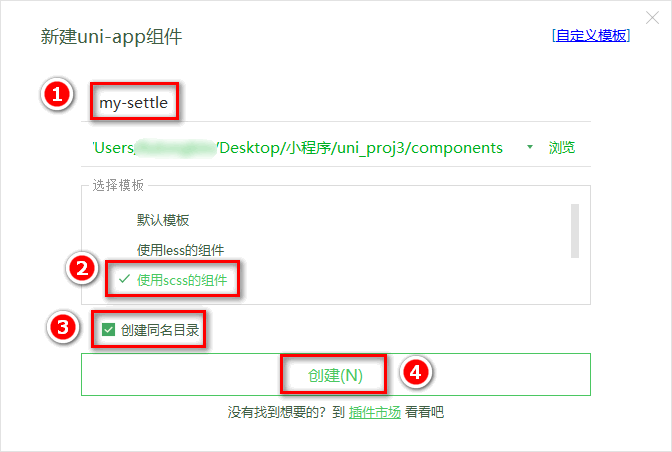


先用一个固定在底部、高 50px 的盒子确认位置，课程初始背景色用 `cyan`：

```vue
<template>
  <!-- 最外层的容器 -->
  <view class="my-settle-container">
    结算组件
  </view>
</template>

<script>
export default {
  data() {
    return {}
  },
}
</script>

<style lang="scss">
.my-settle-container {
  /* 底部固定定位 */
  position: fixed;
  bottom: 0;
  left: 0;
  /* 设置宽高和背景色 */
  width: 100%;
  height: 50px;
  background-color: cyan;
}
</style>
```

在 `pages/cart/cart.vue` 的根容器添加 `class="cart-container"`，商品列表后放入 `<my-settle>`；页面底部留出同样的 50px，防止商品被固定栏盖住：

```html
<template>
  <view class="cart-container">
    <!-- 使用自定义的 address 组件 -->

    <!-- 购物车商品列表的标题区域 -->

    <!-- 商品列表区域 -->

    <!-- 结算区域 -->
    <my-settle></my-settle>
  </view>
</template>

<style lang="scss">
.cart-container {
  padding-bottom: 50px;
}
</style>
```

这里显示的是模板和样式片段，保留原页面的 `<script>`、收货地址和商品列表代码。


### 9.3.2 渲染结算区域的结构和样式

把占位文字改为全选、合计和结算按钮，初期先使用静态值：

```html
<!-- 最外层的容器 -->
<view class="my-settle-container">
  <!-- 全选区域 -->
  <label class="radio">
    <radio color="#C00000" :checked="true" /><text>全选</text>
  </label>

  <!-- 合计区域 -->
  <view class="amount-box">
    合计:<text class="amount">￥1234.00</text>
  </view>

  <!-- 结算按钮 -->
  <view class="btn-settle">结算(0)</view>
</view>
```

用 Flex 让三块内容横向排列，背景改为白色，结算按钮使用主题红：

```scss
.my-settle-container {
  position: fixed;
  bottom: 0;
  left: 0;
  width: 100%;
  height: 50px;
  // 将背景色从 cyan 改为 white
  background-color: white;
  display: flex;
  justify-content: space-between;
  align-items: center;
  padding-left: 5px;
  font-size: 14px;

  .radio {
    display: flex;
    align-items: center;
  }

  .amount {
    color: #c00000;
  }

  .btn-settle {
    height: 50px;
    min-width: 100px;
    background-color: #c00000;
    color: white;
    line-height: 50px;
    text-align: center;
    padding: 0 10px;
  }
}
```

结算栏、按钮均高 50px，按钮最小宽度 100px；后面逐步把 `true`、`1234.00`、`0` 换成 Store 中计算的值。


### 9.3.3 动态渲染已勾选商品的总数量

在 `store/cart.js` 的 `getters` 中新增 `checkedCount`：先筛选 `goods_state` 为真的商品，再累加每件商品的数量。

```javascript
export default {
  getters: {
    // 勾选的商品的总数量
    checkedCount(state) {
      // 先使用 filter 方法，从购物车中过滤器已勾选的商品
      // 再使用 reduce 方法，将已勾选的商品总数量进行累加
      // reduce() 的返回值就是已勾选的商品的总数量
      return state.cart.filter(x => x.goods_state).reduce((total, item) => total += item.goods_count, 0)
    }
  }
}
```

`reduce(..., 0)` 的初值是 0，空数组也会得到 0。统计的是商品**总件数**，不是商品种类数；一个勾选商品的数量为 3，就计入 3。

在 `my-settle.vue` 中导入并映射 getter：

```javascript
import { mapGetters } from 'vuex'

export default {
  computed: {
    ...mapGetters('m_cart', ['checkedCount']),
  },
  data() {
    return {}
  },
}
```

结算按钮改为：

```html
<!-- 结算按钮 -->
<view class="btn-settle">结算({{checkedCount}})</view>
```

勾选、取消勾选或修改数量时，结算括号内的数值随计算属性更新。


### 9.3.4 动态渲染全选按钮的选中状态

把已有的 `total` getter 也映射到结算组件。`total` 是所有商品的件数，`checkedCount` 是已选件数，二者相等时说明全部勾选：

```javascript
import { mapGetters } from 'vuex'

export default {
  computed: {
    // 1. 将 total 映射到当前组件中
    ...mapGetters('m_cart', ['checkedCount', 'total']),
    // 2. 是否全选
    isFullCheck() {
      return this.total === this.checkedCount
    },
  },
  data() {
    return {}
  },
}
```

将 radio 的 `checked` 绑定为计算属性：

```html
<!-- 全选区域 -->
<label class="radio">
  <radio color="#C00000" :checked="isFullCheck" /><text>全选</text>
</label>
```

这个判断依赖课程前面数量至少为 1 的约定。空购物车时两者都是 0，比较也会得到 `true`；9.3.8 会让空购物车不渲染结算组件。


### 9.3.5 实现商品的全选/反选功能

在 `store/cart.js` 的 `mutations` 中增加批量状态更新，更新后同样持久化：

```javascript
export default {
  mutations: {
    // 更新所有商品的勾选状态
    updateAllGoodsState(state, newState) {
      // 循环更新购物车中每件商品的勾选状态
      state.cart.forEach(x => x.goods_state = newState)
      // 持久化存储到本地
      this.commit('m_cart/saveToStorage')
    }
  }
}
```

在 `my-settle.vue` 中映射 mutation：

```javascript
// 1. 按需导入 mapMutations 辅助函数
import { mapGetters, mapMutations } from 'vuex'

export default {
  // 省略其它代码
  methods: {
    // 2. 使用 mapMutations 辅助函数，把 m_cart 模块提供的 updateAllGoodsState 方法映射到当前组件中使用
    ...mapMutations('m_cart', ['updateAllGoodsState']),
  },
}
```

给 `label` 绑定点击事件，使文字和按钮区域都能操作：

```html
<!-- 全选区域 -->
<label class="radio" @click="changeAllState">
  <radio color="#C00000" :checked="isFullCheck" /><text>全选</text>
</label>
```

处理函数把当前全选状态取反，作为所有商品的新状态：

```javascript
export default {
  methods: {
    ...mapMutations('m_cart', ['updateAllGoodsState']),
    // label 的点击事件处理函数
    changeAllState() {
      // 修改购物车中所有商品的选中状态
      // !this.isFullCheck 表示：当前全选按钮的状态取反之后，就是最新的勾选状态
      this.updateAllGoodsState(!this.isFullCheck)
    }
  }
}
```

当前未全选时点击，所有商品变为已选；当前全选时点击，全部取消。状态变化会同时影响单行 radio、选中件数和金额。


### 9.3.6 动态渲染已勾选商品的总价格

在 `store/cart.js` 的 `getters` 中增加 `checkedGoodsAmount`，只计算已勾选商品的“数量 × 单价”：

```javascript
export default {
  getters: {
    // 已勾选的商品的总价
    checkedGoodsAmount(state) {
      // 先使用 filter 方法，从购物车中过滤器已勾选的商品
      // 再使用 reduce 方法，将已勾选的商品数量 * 单价之后，进行累加
      // reduce() 的返回值就是已勾选的商品的总价
      // 最后调用 toFixed(2) 方法，保留两位小数
      return state.cart.filter(x => x.goods_state)
                       .reduce((total, item) => total += item.goods_count * item.goods_price, 0)
                       .toFixed(2)
    }
  }
}
```

`toFixed(2)` 保留两位小数，返回的是字符串，便于显示金额。没有勾选商品时，结果是 `"0.00"`。

把它加入 `my-settle.vue` 的 `computed` 映射：

```javascript
export default {
  computed: {
    ...mapGetters('m_cart', ['total', 'checkedCount', 'checkedGoodsAmount'])
  }
}
```

页面合计区域改为：

```html
<!-- 合计区域 -->
<view class="amount-box">
  合计:<text class="amount">￥{{checkedGoodsAmount}}</text>
</view>
```

例如勾选商品 A（2 件 × 10 元）和 B（1 件 × 5 元），应显示结算件数 3、金额 `25.00`；取消 B 后变为 2 件、`20.00`。


### 9.3.7 动态计算购物车徽标的数值

此前 `badgeMix` 只在页面 `onShow` 时设置徽标，购物车页内修改数量不会自动重新设置。打开 `mixins/tabbar-badge.js`，增加对 `total` 的侦听：

```javascript
import { mapGetters } from 'vuex'

// 导出一个 mixin 对象
export default {
  computed: {
    ...mapGetters('m_cart', ['total']),
  },
  watch: {
    // 监听 total 值的变化
    total() {
      // 调用 methods 中的 setBadge 方法，重新为 tabBar 的数字徽章赋值
      this.setBadge()
    },
  },
  onShow() {
    // 在页面刚展示的时候，设置数字徽标
    this.setBadge()
  },
  methods: {
    setBadge() {
      // 调用 uni.setTabBarBadge() 方法，为购物车设置右上角的徽标
      uni.setTabBarBadge({
        index: 2,
        text: this.total + '', // 注意：text 的值必须是字符串，不能是数字
      })
    },
  },
}
```

页面刚显示和总件数变化时都会调用 `setBadge()`。`index: 2` 指购物车 tabBar 项，`text` 必须传字符串，所以用 `this.total + ''`。

包内仍把总数 0 转为字符串 `"0"` 传入，没有新增“0 时移除徽标”的分支；这里沿用原课行为。


### 9.3.8 渲染购物车为空时的页面结构

把包内“资料”目录的 `cart_empty@2x.png` 复制到项目 `static` 中。然后用条件展示区分有商品和无商品：

```html
<template>
  <view class="cart-container" v-if="cart.length !== 0">

    <!-- 使用自定义的 address 组件 -->

    <!-- 购物车商品列表的标题区域 -->

    <!-- 商品列表区域 -->

    <!-- 结算区域 -->

  </view>

  <!-- 空白购物车区域 -->
  <view class="empty-cart" v-else>
    <image src="/static/cart_empty@2x.png" class="empty-img"></image>
    <text class="tip-text">空空如也~</text>
  </view>
</template>
```

已有的地址组件、标题、商品列表和 `my-settle` 全部放在第一个容器内；空数组时切换为图片和“空空如也~”。

空购物车样式：

```scss
.empty-cart {
  display: flex;
  flex-direction: column;
  align-items: center;
  padding-top: 150px;

  .empty-img {
    width: 90px;
    height: 90px;
  }

  .tip-text {
    font-size: 12px;
    color: gray;
    margin-top: 15px;
  }
}
```

删除最后一个商品后，应直接显示空状态，地址和结算栏一起隐藏。


## 9.4 购物车分支的合并与提交

以下命令是原课在 `uni-shop-2` 项目根目录的操作步骤。购物车完成并验证后，先提交、推送 `cart`，再合并到主分支：

```bash
git add .
git commit -m "完成了购物车的开发"
git push -u origin cart
git checkout master
git merge cart
git push
git branch -d cart
```

课程远程仓库为码云，主分支名是 `master`；跟课时以自己的远程地址和实际分支为准。这里仅记录命令，没有在当前笔记仓库执行。


## 10. 登录与支付

### 10.0 创建 settle 分支

在课程项目根目录、完成 `cart` 合并后的 `master` 分支上创建新分支，集中开发登录和支付：

```bash
git checkout -b settle
```

### 10.1 点击结算按钮进行条件判断

结算之前必须按顺序判断：勾选商品 → 选择收货地址 → 已登录。给 `my-settle.vue` 的按钮绑定：

```html
<!-- 结算按钮 -->
<view class="btn-settle" @click="settlement">结算({{checkedCount}})</view>
```

此阶段 `settlement` 的条件如下：

```javascript
export default {
  methods: {
    // 点击了结算按钮
    settlement() {
      // 1. 先判断是否勾选了要结算的商品
      if (!this.checkedCount) return uni.$showMsg('请选择要结算的商品！')

      // 2. 再判断用户是否选择了收货地址
      if (!this.addstr) return uni.$showMsg('请选择收货地址！')

      // 3. 最后判断用户是否登录了
      if (!this.token) return uni.$showMsg('请先登录！')
    }
  }
}
```

每个失败分支都 `return`，所以只提示第一个不满足的条件；条件未通过时不会继续发起订单请求。


`my-settle.vue` 已从 `m_cart` 获取件数和金额，还需要从 `m_user` 获取地址 getter 和登录 Token。

先在 `store/user.js` 的 `state` 中加入 `token: ''`，保留已有地址数据；再在结算组件导入 `mapState`：

```javascript
// 按需从 vuex 中导入 mapState 辅助函数
import { mapGetters, mapMutations, mapState } from 'vuex'

export default {
  computed: {
    ...mapGetters('m_cart', ['total', 'checkedCount', 'checkedGoodsAmount']),
    ...mapGetters('m_user', ['addstr']),
    // token 是用户登录成功之后的 token 字符串
    ...mapState('m_user', ['token']),
    isFullCheck() {
      return this.total === this.checkedCount
    },
  },
}
```

`addstr` 是 09 拼出的详细收货地址，空字符串表示未选地址。此处用 Token 是否为空作为课程的登录判据；后面成功登录会更新并保存 Token。


## 10.2 登录

### 10.2.1 定义 my 页面的编译模式

在微信开发者工具中选择“添加编译模式”，模式名称和启动页面都填 `pages/my/my`，启动参数留空。

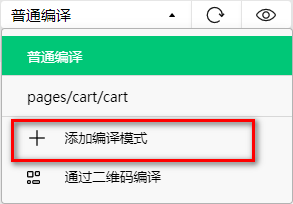

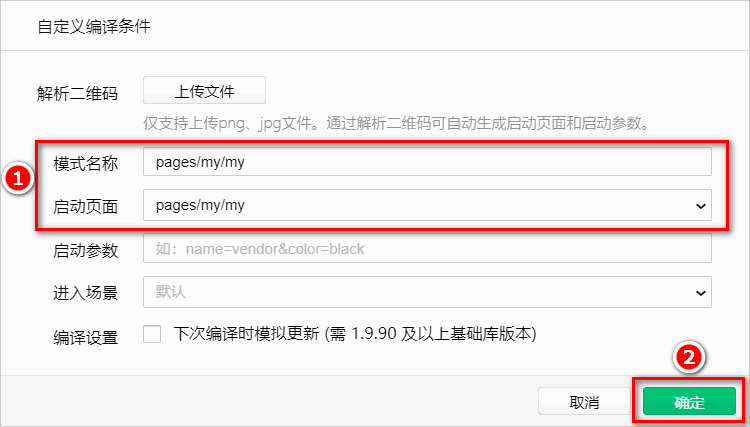


### 10.2.2 实现登录和用户信息组件的按需展示

在 `components` 下新建两个组件，都选 scss 和同名目录：

- `my-login`：用户未登录时显示授权按钮。
- `my-userinfo`：登录后显示头像、昵称和个人中心面板。

包内讲义的新建登录组件截图：

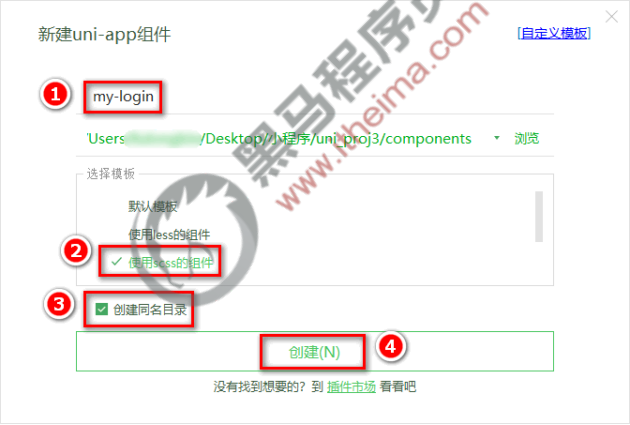


用户信息组件对应路径为 `components/my-userinfo/my-userinfo.vue`：

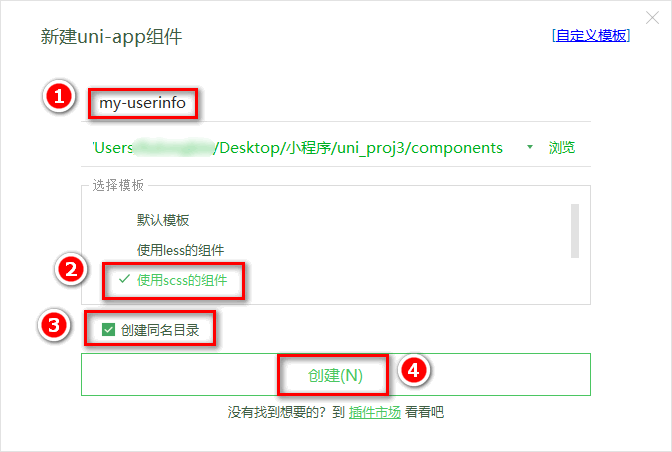


在 `pages/my/my.vue` 中保留 `badgeMix`，用 `mapState` 读取 Token：

```javascript
import badgeMix from '@/mixins/tabbar-badge.js'
// 1. 从 vuex 中按需导入 mapState 辅助函数
import { mapState } from 'vuex'

export default {
  mixins: [badgeMix],
  computed: {
    // 2. 从 m_user 模块中导入需要的 token 字符串
    ...mapState('m_user', ['token']),
  },
  data() {
    return {}
  },
}
```

模板按 Token 是否为空切换两个组件：

```html
<template>
  <view>

    <!-- 用户未登录时，显示登录组件 -->
    <my-login v-if="!token"></my-login>

    <!-- 用户登录后，显示用户信息组件 -->
    <my-userinfo v-else></my-userinfo>

  </view>
</template>
```

Token 为空时显示登录界面，非空时显示用户信息；用户头像数据已获取并不等于已经拿到登录 Token。


### 10.2.3 实现登录组件的基本布局

在 `my-login.vue` 中放联系人图标、登录按钮和提示文字：

```html
<template>
  <view class="login-container">
    <!-- 提示登录的图标 -->
    <uni-icons type="contact-filled" size="100" color="#AFAFAF"></uni-icons>
    <!-- 登录按钮 -->
    <button type="primary" class="btn-login">一键登录</button>
    <!-- 登录提示 -->
    <view class="tips-text">登录后尽享更多权益</view>
  </view>
</template>
```

用纵向 Flex 居中，按钮宽 90%，底部用伪元素做半椭圆造型：

```scss
.login-container {
  // 登录盒子的样式
  height: 750rpx;
  display: flex;
  flex-direction: column;
  align-items: center;
  justify-content: center;
  background-color: #f8f8f8;
  position: relative;
  overflow: hidden;

  // 绘制登录盒子底部的半椭圆造型
  &::after {
    content: ' ';
    display: block;
    position: absolute;
    width: 100%;
    height: 40px;
    left: 0;
    bottom: 0;
    background-color: white;
    border-radius: 100%;
    transform: translateY(50%);
  }

  // 登录按钮的样式
  .btn-login {
    width: 90%;
    border-radius: 100px;
    margin: 15px 0;
    background-color: #c00000;
  }

  // 按钮下方提示消息的样式
  .tips-text {
    font-size: 12px;
    color: gray;
  }
}
```

`position: relative` 为伪元素提供定位基准，`overflow: hidden` 裁掉超出盒子的部分；伪元素下移 50%，只露出上半部。


### 10.2.4 点击登录按钮获取微信用户的基本信息

课程给按钮增加 `open-type="getUserInfo"`，在 `@getuserinfo` 中接收授权结果：

```html
<!-- 登录按钮 -->
<!-- 可以从 @getuserinfo 事件处理函数的形参中，获取到用户的基本信息 -->
<button type="primary" class="btn-login" open-type="getUserInfo" @getuserinfo="getUserInfo">一键登录</button>
```

先判断用户是否拒绝授权，再读取 `e.detail.userInfo`：

```javascript
export default {
  methods: {
    // 获取微信用户的基本信息
    getUserInfo(e) {
      // 判断是否获取用户信息成功
      if (e.detail.errMsg === 'getUserInfo:fail auth deny') return uni.$showMsg('您取消了登录授权！')

      // 获取用户信息成功， e.detail.userInfo 就是用户的基本信息
      console.log(e.detail.userInfo)
    }
  }
}
```

用户信息中的 `avatarUrl`、`nickName` 用于显示头像和昵称；后面换取 Token 时传的是整个 `e.detail`，还需要其中的加密与签名字段。

> 这是 2020 年资料中的授权方式。微信头像昵称获取规则后来有变化，不能把旧版 `getUserInfo` 按钮的行为视为当前环境保证；本篇保留课程实现，未换成另一套登录流程。


### 10.2.5 将用户的基本信息存储到 Vuex

在 `store/user.js` 的 `state` 增加 `userinfo`，初始化时从缓存恢复：

```javascript
export default {
  // state 数据
  state: () => ({
    // 收货地址
    // address: {}
    address: JSON.parse(uni.getStorageSync('address') || '{}'),
    // 登录成功之后的 token 字符串
    token: '',
    // 用户的基本信息
    userinfo: JSON.parse(uni.getStorageSync('userinfo') || '{}')
  }),
}
```

新增更新和保存的 mutation，保留已有的地址方法：

```javascript
export default {
  // 方法
  mutations: {
    // 省略其它代码...

    // 更新用户的基本信息
    updateUserInfo(state, userinfo) {
      state.userinfo = userinfo
      // 通过 this.commit() 方法，调用 m_user 模块下的 saveUserInfoToStorage 方法，将 userinfo 对象持久化存储到本地
      this.commit('m_user/saveUserInfoToStorage')
    },

    // 将 userinfo 持久化存储到本地
    saveUserInfoToStorage(state) {
      uni.setStorageSync('userinfo', JSON.stringify(state.userinfo))
    }
  }
}
```

在 `my-login.vue` 中通过 `mapMutations` 映射 `updateUserInfo`，成功授权后调用它：

```javascript
// 1. 按需导入 mapMutations 辅助函数
import { mapMutations } from 'vuex'

export default {
  data() {
    return {}
  },
  methods: {
    // 2. 调用 mapMutations 辅助方法，把 m_user 模块中的 updateUserInfo 映射到当前组件中使用
    ...mapMutations('m_user', ['updateUserInfo']),
    // 获取微信用户的基本信息
    getUserInfo(e) {
      // 判断是否获取用户信息成功
      if (e.detail.errMsg === 'getUserInfo:fail auth deny') return uni.$showMsg('您取消了登录授权！')
      // 获取用户信息成功， e.detail.userInfo 就是用户的基本信息
      // console.log(e.detail.userInfo)

      // 3. 将用户的基本信息存储到 vuex 中
      this.updateUserInfo(e.detail.userInfo)
    },
  },
}
```

用户信息对象序列化后存入 `userinfo` 键。组件显示和本地保存都由这次 mutation 驱动，重启后会用 `JSON.parse()` 恢复。


### 10.2.6 登录获取 Token 字符串

获取头像昵称后，还需要调用登录接口取得服务端的身份凭证。在 `getUserInfo` 更新用户信息后，调用 `getToken(e.detail)`：

```javascript
export default {
  methods: {
    // 获取微信用户的基本信息
    getUserInfo(e) {
      // 判断是否获取用户信息成功
      if (e.detail.errMsg === 'getUserInfo:fail auth deny') return uni.$showMsg('您取消了登录授权！')

      // 将用户的基本信息存储到 vuex 中
      this.updateUserInfo(e.detail.userInfo)

      // 获取登录成功后的 Token 字符串
      this.getToken(e.detail)
    }
  }
}
```

`getToken` 先通过 `uni.login()` 取得临时 `code`，再把 `code` 和授权数据提交给课程服务端：

```javascript
export default {
  methods: {
    // 调用登录接口，换取永久的 token
    async getToken(info) {
      // 调用微信登录接口
      const [err, res] = await uni.login().catch(err => err)
      // 判断是否 uni.login() 调用失败
      if (err || res.errMsg !== 'login:ok') return uni.$showMsg('登录失败！')

      // 准备参数对象
      const query = {
        code: res.code,
        encryptedData: info.encryptedData,
        iv: info.iv,
        rawData: info.rawData,
        signature: info.signature
      }

      // 换取 token
      const { data: loginResult } = await uni.$http.post('/api/public/v1/users/wxlogin', query)
      if (loginResult.meta.status !== 200) return uni.$showMsg('登录失败！')
      uni.$showMsg('登录成功')
    }
  }
}
```

| 请求字段 | 来源与用途 |
| --- | --- |
| `code` | `uni.login()` 成功返回的临时登录凭证 |
| `encryptedData` | `e.detail` 中的完整用户信息密文 |
| `iv` | 加密算法初始向量 |
| `rawData` | 原始用户信息字符串 |
| `signature` | 用户数据签名 |

调用路径为 `POST /api/public/v1/users/wxlogin`，业务状态 `meta.status` 等于 200 时才进入成功逻辑。课程后端返回 `message.token`。

> 讲义此处失败提示调用 `$showError`，但项目 `main.js` 只定义了 `$showMsg`，包内 `my-login.vue` 也使用 `$showMsg`，上面已按源码修正。讲义称“永久 Token”，这是原课服务端约定；不等于所有登录系统中的 Token 都不会过期。


### 10.2.7 将 Token 存储到 Vuex

在 `store/user.js` 中增加 `updateToken` 和 `saveTokenToStorage`：

```javascript
export default {
  mutations: {
    // 省略其它代码...

    // 更新 token 字符串
    updateToken(state, token) {
      state.token = token
      // 通过 this.commit() 方法，调用 m_user 模块下的 saveTokenToStorage 方法，将 token 字符串持久化存储到本地
      this.commit('m_user/saveTokenToStorage')
    },

    // 将 token 字符串持久化存储到本地
    saveTokenToStorage(state) {
      uni.setStorageSync('token', state.token)
    }
  }
}
```

把 `state.token` 改为读取缓存，Token 已经是字符串，不需要 JSON 序列化：

```javascript
export default {
  // state 数据
  state: () => ({
    // 收货地址
    address: JSON.parse(uni.getStorageSync('address') || '{}'),
    // 登录成功之后的 token 字符串
    token: uni.getStorageSync('token') || '',
    // 用户的基本信息
    userinfo: JSON.parse(uni.getStorageSync('userinfo') || '{}')
  }),
}
```

在 `my-login.vue` 中映射 `updateToken`，接口成功后保存返回值：

```javascript
export default {
  methods: {
    // 1. 使用 mapMutations 辅助方法，把 m_user 模块中的 updateToken 方法映射到当前组件中使用
    ...mapMutations('m_user', ['updateUserInfo', 'updateToken']),

    // 省略其它代码...

    // 调用登录接口，换取永久的 token
    async getToken(info) {
      // 调用微信登录接口
      const [err, res] = await uni.login().catch(err => err)
      // 判断是否 uni.login() 调用失败
      if (err || res.errMsg !== 'login:ok') return uni.$showMsg('登录失败！')

      // 准备参数对象
      const query = {
        code: res.code,
        encryptedData: info.encryptedData,
        iv: info.iv,
        rawData: info.rawData,
        signature: info.signature
      }

      // 换取 token
      const { data: loginResult } = await uni.$http.post('/api/public/v1/users/wxlogin', query)
      if (loginResult.meta.status !== 200) return uni.$showMsg('登录失败！')

      // 2. 更新 vuex 中的 token
      this.updateToken(loginResult.message.token)
    }
  }
}
```

> 原讲义 `mapMutations` 展开项之后漏了逗号，导致它与后面的 `getToken` 方法无法构成合法对象；上面补齐了逗号，并按源码修正提示方法。

Token 更新后，“我的”页的 `v-if` 随即切换到用户信息组件。重启项目也会从本地 `token` 键恢复登录判据。


## 10.3 用户信息

### 10.3.1 实现用户头像昵称区域的基本布局

在 `my-userinfo.vue` 中先创建顶部头像昵称区：

```html
<template>
  <view class="my-userinfo-container">

    <!-- 头像昵称区域 -->
    <view class="top-box">
      <image src="" class="avatar"></image>
      <view class="nickname">xxx</view>
    </view>

  </view>
</template>
```

组件整体浅灰，顶部主题红，头像设为圆形、白色边框并添加阴影：

```scss
.my-userinfo-container {
  height: 100%;
  // 为整个组件的结构添加浅灰色的背景
  background-color: #f4f4f4;

  .top-box {
    height: 400rpx;
    background-color: #c00000;
    display: flex;
    flex-direction: column;
    align-items: center;
    justify-content: center;

    .avatar {
      display: block;
      width: 90px;
      height: 90px;
      border-radius: 45px;
      border: 2px solid white;
      box-shadow: 0 1px 5px black;
    }

    .nickname {
      color: white;
      font-weight: bold;
      font-size: 16px;
      margin-top: 10px;
    }
  }
}
```

在 `pages/my/my.vue` 根容器加入 `class="my-container"`，并同时设置页面和容器高度，保证用户信息组件的 `height: 100%` 有对应父级高度：

```scss
page,
.my-container {
  height: 100%;
}
```


### 10.3.2 渲染用户的头像和昵称

在 `my-userinfo.vue` 中从 `m_user` 映射用户信息：

```javascript
// 按需导入 mapState 辅助函数
import { mapState } from 'vuex'

export default {
  computed: {
    // 将 m_user 模块中的 userinfo 映射到当前页面中使用
    ...mapState('m_user', ['userinfo']),
  },
  data() {
    return {}
  },
}
```

替换静态图片地址和昵称：

```html
<!-- 头像昵称区域 -->
<view class="top-box">
  <image :src="userinfo.avatarUrl" class="avatar"></image>
  <view class="nickname">{{userinfo.nickName}}</view>
</view>
```

头像绑定 `userinfo.avatarUrl`，昵称绑定 `userinfo.nickName`。显示的是已存入 Vuex 的数据。


### 10.3.3 渲染第一个面板区域

在顶部区域之后新增 `panel-list`，第一个面板展示收藏店铺、收藏商品、关注商品和足迹：

```html
<!-- 面板的列表区域 -->
<view class="panel-list">
  <!-- 第一个面板 -->
  <view class="panel">
    <!-- panel 的主体区域 -->
    <view class="panel-body">
      <!-- panel 的 item 项 -->
      <view class="panel-item">
        <text>8</text>
        <text>收藏的店铺</text>
      </view>
      <view class="panel-item">
        <text>14</text>
        <text>收藏的商品</text>
      </view>
      <view class="panel-item">
        <text>18</text>
        <text>关注的商品</text>
      </view>
      <view class="panel-item">
        <text>84</text>
        <text>足迹</text>
      </view>
    </view>
  </view>

  <!-- 第二个面板 -->

  <!-- 第三个面板 -->
</view>
```

样式让面板稍微上移，与顶部相接；每个条目上下展示数量与文字：

```scss
.panel-list {
  padding: 0 10px;
  position: relative;
  top: -10px;

  .panel {
    background-color: white;
    border-radius: 3px;
    margin-bottom: 8px;

    .panel-body {
      display: flex;
      justify-content: space-around;

      .panel-item {
        display: flex;
        flex-direction: column;
        align-items: center;
        justify-content: space-around;
        font-size: 13px;
        padding: 10px 0;
      }
    }
  }
}
```

这里的 8、14、18、84 是课程静态展示数字，没有读取收藏接口。


### 10.3.4 渲染第二个面板区域

在 `panel-list` 内增加“我的订单”面板，使用 `static/my-icons/icon1.png` 到 `icon4.png`：

```html
<!-- 第二个面板 -->
<view class="panel">
  <!-- 面板的标题 -->
  <view class="panel-title">我的订单</view>
  <!-- 面板的主体 -->
  <view class="panel-body">
    <!-- 面板主体中的 item 项 -->
    <view class="panel-item">
      <image src="/static/my-icons/icon1.png" class="icon"></image>
      <text>待付款</text>
    </view>
    <view class="panel-item">
      <image src="/static/my-icons/icon2.png" class="icon"></image>
      <text>待收货</text>
    </view>
    <view class="panel-item">
      <image src="/static/my-icons/icon3.png" class="icon"></image>
      <text>退款/退货</text>
    </view>
    <view class="panel-item">
      <image src="/static/my-icons/icon4.png" class="icon"></image>
      <text>全部订单</text>
    </view>
  </view>
</view>
```

在已有 `.panel` 中增加标题样式，在 `.panel-item` 中增加 `.icon`，完整对应样式如下：

```scss
.panel-list {
  padding: 0 10px;
  position: relative;
  top: -10px;

  .panel {
    background-color: white;
    border-radius: 3px;
    margin-bottom: 8px;

    .panel-title {
      line-height: 45px;
      padding-left: 10px;
      font-size: 15px;
      border-bottom: 1px solid #f4f4f4;
    }

    .panel-body {
      display: flex;
      justify-content: space-around;

      .panel-item {
        display: flex;
        flex-direction: column;
        align-items: center;
        justify-content: space-around;
        font-size: 13px;
        padding: 10px 0;

        .icon {
          width: 35px;
          height: 35px;
        }
      }
    }
  }
}
```

图标 35px × 35px，四个入口为待付款、待收货、退款/退货、全部订单。本天只完成展示布局，未为它们实现订单列表跳转。


### 10.3.5 渲染第三个面板区域

第三个面板是三行列表：收货地址、联系客服、退出登录，右侧都放箭头：

```html
<!-- 第三个面板 -->
<view class="panel">
  <view class="panel-list-item">
    <text>收货地址</text>
    <uni-icons type="arrowright" size="15"></uni-icons>
  </view>
  <view class="panel-list-item">
    <text>联系客服</text>
    <uni-icons type="arrowright" size="15"></uni-icons>
  </view>
  <view class="panel-list-item">
    <text>退出登录</text>
    <uni-icons type="arrowright" size="15"></uni-icons>
  </view>
</view>
```

给每行设置高 45px 和左右对齐：

```scss
.panel-list-item {
  height: 45px;
  display: flex;
  justify-content: space-between;
  align-items: center;
  font-size: 15px;
  padding: 0 10px;
}
```

包内完成版用 `line-height: 45px`，讲义用 `height: 45px`；下一节只给退出登录实现行为，另两行仍为布局。


### 10.3.6 实现退出登录的功能

给退出项绑定 `@click="logout"`：

```html
<view class="panel-list-item" @click="logout">
  <text>退出登录</text>
  <uni-icons type="arrowright" size="15"></uni-icons>
</view>
```

组件导入并映射需要的三种用户 mutation：

```javascript
// 按需导入辅助函数
import { mapState, mapMutations } from 'vuex'

export default {
  methods: {
    ...mapMutations('m_user', ['updateUserInfo', 'updateToken', 'updateAddress']),
  },
}
```

在 `methods` 中新增确认逻辑：

```javascript
export default {
  methods: {
    // 退出登录
    async logout() {
      // 询问用户是否退出登录
      const [err, succ] = await uni.showModal({
        title: '提示',
        content: '确认退出登录吗？'
      }).catch(err => err)

      if (succ && succ.confirm) {
         // 用户确认了退出登录的操作
         // 需要清空 vuex 中的 userinfo、token 和 address
         this.updateUserInfo({})
         this.updateToken('')
         this.updateAddress({})
      }
    }
  }
}
```

用户确认后清空 `userinfo`、`token`、`address`，对应 mutation 同步更新本地缓存；Token 变空，“我的”页切回登录组件。取消确认时保留原数据。此处没有清空购物车。


## 10.4 三秒后自动跳转

### 10.4.1 三秒后自动跳转到登录页面

需求：购物车满足商品和地址条件但没有 Token 时，提示倒计时，三秒后切换到“我的”页登录。

在 `my-settle.vue` 的 `methods` 中新增消息方法：

```javascript
export default {
  methods: {
    // 展示倒计时的提示消息
    showTips(n) {
      // 调用 uni.showToast() 方法，展示提示消息
      uni.showToast({
        // 不展示任何图标
        icon: 'none',
        // 提示的消息
        title: '请登录后再结算！' + n + ' 秒后自动跳转到登录页',
        // 为页面添加透明遮罩，防止点击穿透
        mask: true,
        // 1.5 秒后自动消失
        duration: 1500
      })
    }
  }
}
```

`mask: true` 防止提示期间点击穿透，`duration: 1500` 是单次提示显示时长。它与定时器每隔 1000ms 更新一次不是同一个含义。

在 `data` 中声明秒数和定时器 ID：

```javascript
export default {
  data() {
    return {
      // 倒计时的秒数
      seconds: 3,
      // 定时器的 Id
      timer: null
    }
  }
}
```

将 `settlement` 最后一个未登录判断替换为 `if (!this.token) return this.delayNavigate()`，保留前两个条件。


课程逐步修正倒计时的两个问题：

1. 只用 `setInterval()` 减少秒数，定时器不会停，会出现 0 或负数。
2. 增加停止和跳转后，如果不重置 `seconds`，第二次调用仍会从 0 开始。

最终在每次调用开始时重置为 3，并在秒数小于等于 0 时清理定时器、跳转、提前返回：

```javascript
export default {
  methods: {
    // 延迟导航到 my 页面
    delayNavigate() {
      // 把 data 中的秒数重置成 3 秒
      this.seconds = 3
      this.showTips(this.seconds)

      this.timer = setInterval(() => {
        this.seconds--

        if (this.seconds <= 0) {
          clearInterval(this.timer)
          uni.switchTab({
            url: '/pages/my/my'
          })
          return
        }

        this.showTips(this.seconds)
      }, 1000)
    }
  }
}
```

应看到 3 → 2 → 1 的提示，然后进入 `pages/my/my`，不会再显示 0 秒提示。因为目标是 tabBar 页面，使用 `uni.switchTab()`。

这段是课程最终的正常点击流程，未包含组件销毁或重复启动时的额外定时器清理。


### 10.4.2 登录成功之后再返回之前的页面

为了从登录页返回购物车，在 `store/user.js` 中增加临时重定向信息：

```javascript
export default {
  // state 数据
  state: () => ({
    // 收货地址
    address: JSON.parse(uni.getStorageSync('address') || '{}'),
    // 登录成功之后的 token 字符串
    token: uni.getStorageSync('token') || '',
    // 用户的基本信息
    userinfo: JSON.parse(uni.getStorageSync('userinfo') || '{}'),
    // 重定向的 object 对象 { openType, from }
    redirectInfo: null
  }),
}
```

新增 mutation：

```javascript
export default {
  mutations: {
    // 更新重定向的信息对象
    updateRedirectInfo(state, info) {
      state.redirectInfo = info
    }
  }
}
```

`redirectInfo` 的两个字段：`openType` 表示返回方式，`from` 表示原页面 URL。初始为 `null`，本课没有把它写入本地缓存。

在 `my-settle.vue` 中映射：

```javascript
export default {
  methods: {
    // 把 m_user 模块中的 updateRedirectInfo 方法映射到当前页面中使用
    ...mapMutations('m_user', ['updateRedirectInfo']),
  }
}
```

修改 `delayNavigate`，切到“我的”页成功后记录返回信息：

```javascript
export default {
  methods: {
    // 延迟导航到 my 页面
    delayNavigate() {
      // 把 data 中的秒数重置成 3 秒
      this.seconds = 3
      this.showTips(this.seconds)

      this.timer = setInterval(() => {
        this.seconds--

        if (this.seconds <= 0) {
          // 清除定时器
          clearInterval(this.timer)
          // 跳转到 my 页面
          uni.switchTab({
            url: '/pages/my/my',
            // 页面跳转成功之后的回调函数
            success: () => {
              // 调用 vuex 的 updateRedirectInfo 方法，把跳转信息存储到 Store 中
              this.updateRedirectInfo({
                // 跳转的方式
                openType: 'switchTab',
                // 从哪个页面跳转过去的
                from: '/pages/cart/cart'
              })
            }
          })

          return
        }

        this.showTips(this.seconds)
      }, 1000)
    }
  }
}
```


在 `my-login.vue` 中读取 `redirectInfo` 并映射更新方法：

```javascript
// 按需导入辅助函数
import { mapMutations, mapState } from 'vuex'

export default {
  computed: {
    // 调用 mapState 辅助方法，把 m_user 模块中的数据映射到当前用组件中使用
    ...mapState('m_user', ['redirectInfo']),
  },
  methods: {
    // 调用 mapMutations 辅助方法，把 m_user 模块中的方法映射到当前组件中使用
    ...mapMutations('m_user', ['updateUserInfo', 'updateToken', 'updateRedirectInfo']),
  },
}
```

`getToken` 成功保存 Token 后，紧接着调用 `this.navigateBack()`；失败分支已提前返回，不执行该调用。

新增返回方法：

```javascript
export default {
  methods: {
    // 返回登录之前的页面
    navigateBack() {
      // redirectInfo 不为 null，并且导航方式为 switchTab
      if (this.redirectInfo && this.redirectInfo.openType === 'switchTab') {
        // 调用小程序提供的 uni.switchTab() API 进行页面的导航
        uni.switchTab({
          // 要导航到的页面地址
          url: this.redirectInfo.from,
          // 导航成功之后，把 vuex 中的 redirectInfo 对象重置为 null
          complete: () => {
            this.updateRedirectInfo(null)
          }
        })
      }
    }
  }
}
```

直接从“我的”页登录时，`redirectInfo` 为 `null`，不会自动返回；从购物车的倒计时进入时，则切回 `/pages/cart/cart`。

> 讲义注释写“导航成功之后清空”，但实际用的是 `complete` 回调，导航成功或失败都会执行。这里按实际代码解释：导航调用结束后把信息重置为 `null`，避免下次登录沿用旧记录。


## 10.5 微信支付

### 10.5.1 在请求头中添加 Token 身份认证的字段

包内 API 文档规定 `/api/public/v1/my` 下的接口只允许已登录用户访问。在项目 `main.js` 中保留原请求拦截器的 loading 提示，并在 URL 包含 `/my/` 时添加认证头：

```javascript
// 请求开始之前做一些事情
$http.beforeRequest = function(options) {
  uni.showLoading({
    title: '数据加载中...',
  })

  // 判断请求的是否为有权限的 API 接口
  if (options.url.indexOf('/my/') !== -1) {
    // 为请求头添加身份认证字段
    options.header = {
      // 字段的值可以直接从 vuex 中进行获取
      Authorization: store.state.m_user.token,
    }
  }
}
```

`store` 已在 `main.js` 导入，Token 从 `store.state.m_user.token` 读取。这里按服务端返回的完整 Token 设置 `Authorization`，不要自行重复添加前缀。

原课直接替换 `options.header` 为认证头对象，适用于当前示例；若已有其他请求头，直接替换会覆盖它们。响应拦截器仍保留 `uni.hideLoading()`。


### 10.5.2 微信支付的流程

课程支付分为三步，之后再查一次服务端结果：

| 顺序 | 操作 | 输入 | 得到的结果 |
| --- | --- | --- | --- |
| 1 | 创建订单 | 金额、收货地址、勾选商品 | `order_number` |
| 2 | 请求订单预支付 | 订单编号 | `message.pay` 支付参数对象 |
| 3 | `uni.requestPayment(payInfo)` | 预支付参数对象 | 支付调用成功或失败 |
| 4 | 查询订单支付状态 | 同一个订单编号 | 服务端业务状态 |

讲义先介绍 `requestPayment` 的 `success`、`fail`、`complete` 回调，再在代码中使用课程版本的 Promise 返回数组 `[err, succ]`。支付参数 `timeStamp`、`nonceStr`、`package`、`signType`、`paySign` 来自服务端，不由前端自行生成。

登录和支付需要与课程后端相匹配的微信 AppId 和相关服务配置；有代码并不保证任意测试 AppId 都能完成这条链路。


### 10.5.3 创建订单

在 `my-settle.vue` 的 `computed` 额外映射 `m_cart/cart`，用于构造订单商品数组：

```javascript
export default {
  computed: {
    ...mapState('m_cart', ['cart'])
  }
}
```

结算三个前提都通过后调用 `payOrder()`：

```javascript
export default {
  methods: {
    // 点击了结算按钮
    settlement() {
      // 1. 先判断是否勾选了要结算的商品
      if (!this.checkedCount) return uni.$showMsg('请选择要结算的商品！')

      // 2. 再判断用户是否选择了收货地址
      if (!this.addstr) return uni.$showMsg('请选择收货地址！')

      // 3. 最后判断用户是否登录了
      // if (!this.token) return uni.$showMsg('请先登录！')
      if (!this.token) return this.delayNavigate()

      // 4. 实现微信支付功能
      this.payOrder()
    },
  }
}
```

`payOrder` 初期先完成创建订单：

```javascript
export default {
  methods: {
    // 微信支付
    async payOrder() {
      // 1. 创建订单
      // 1.1 组织订单的信息对象
      const orderInfo = {
        // 开发期间，注释掉真实的订单价格，
        // order_price: this.checkedGoodsAmount,
        // 写死订单总价为 1 分钱
        order_price: 0.01,
        consignee_addr: this.addstr,
        goods: this.cart.filter(x => x.goods_state).map(x => ({ goods_id: x.goods_id, goods_number: x.goods_count, goods_price: x.goods_price }))
      }
      // 1.2 发起请求创建订单
      const { data: res } = await uni.$http.post('/api/public/v1/my/orders/create', orderInfo)
      if (res.meta.status !== 200) return uni.$showMsg('创建订单失败！')
      // 1.3 得到服务器响应的“订单编号”
      const orderNumber = res.message.order_number

       // 2. 订单预支付

       // 3. 发起微信支付
     }
  }
}
```

只把 `goods_state` 为真的商品传给服务器，前端的 `goods_count` 对应接口的 `goods_number`。创建成功取 `res.message.order_number`，失败提示后立即返回。

> 原课开发演示把真实的 `order_price: this.checkedGoodsAmount` 注释掉，写死为 `0.01` 元，即 1 分钱；这是课程测试金额，与页面合计可能不同。本笔记保留这一演示设置，没有发起实际支付。


### 10.5.4 订单预支付

在创建订单后、发起支付前增加以下代码，继续放在同一个异步 `payOrder` 方法内：

```javascript
const { data: res2 } = await uni.$http.post(
  '/api/public/v1/my/orders/req_unifiedorder',
  { order_number: orderNumber }
)
if (res2.meta.status !== 200) return uni.$showMsg('预付订单生成失败！')
const payInfo = res2.message.pay
```

必须使用创建订单返回的 `orderNumber`，不能重新生成或换一个订单号。新版课程 API 文档明确支付对象在 `message.pay`，不是旧接口的 `data.wxorder`。

这里也按包内源码修正了讲义的 `$showError` 为 `$showMsg`。预支付失败就停止，不再调用支付 API。


### 10.5.5 发起微信支付

紧接 `payInfo` 后调用支付，并向服务器确认最终订单状态：

```javascript
const [err, succ] = await uni.requestPayment(payInfo)
if (err) return uni.$showMsg('订单未支付！')

const { data: res3 } = await uni.$http.post(
  '/api/public/v1/my/orders/chkOrder',
  { order_number: orderNumber }
)
if (res3.meta.status !== 200) return uni.$showMsg('订单未支付！')

uni.showToast({
  title: '支付完成！',
  icon: 'success'
})
```

支付调用有错误时直接提示未支付；调用成功后仍要查询 `chkOrder`。只有业务状态为 200，才显示支付完成。

| API | 方法 | 本步骤的关键字段 |
| --- | --- | --- |
| `/api/public/v1/my/orders/create` | POST | `order_price`、`consignee_addr`、`goods` |
| `/api/public/v1/my/orders/req_unifiedorder` | POST | 请求 `order_number`，响应 `message.pay` |
| `/api/public/v1/my/orders/chkOrder` | POST | 请求 `order_number`，检查 `meta.status` |

包内完成版成功文案为“订单支付完成！”，讲义是“支付完成！”。课程完成版没有在成功后删除已购商品或导航到订单详情，这些行为不在本天代码中。


## 10.6 登录与支付分支的合并与提交

在课程项目根目录验证功能后，提交并推送 `settle`，合并到 `master`，最后删除本地子分支：

```bash
git add .
git commit -m "完成了登录和支付功能的开发"
git push -u origin settle
git checkout master
git merge settle
git push
git branch -d settle
```

以上为原课命令，未在本笔记仓库执行。后面的发布流程使用完成并合并后的项目。


## 11. 发布小程序与 Android App

### 11.1 为什么要发布

小程序发布后才能被用户搜索和使用。开发期间为了调试，代码带有 sourcemap 等辅助文件且未压缩，体积较大；发行编译会优化体积和运行性能。

下面按原课界面记录发布流程，截图中的应用名称、AppId、账号和包名是课程示例，实际操作填写自己项目对应的值。


### 11.2 发布小程序的流程

**1. 发行编译。** 在 HBuilderX 菜单栏选择“发行 → 小程序-微信（仅适用于 uni-app）”。

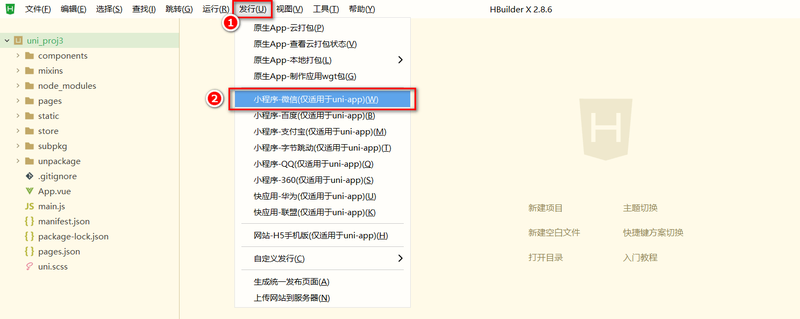


**2. 填写名称和 AppId。** 在弹窗中填写微信小程序名称及对应 AppId，点击“发行”。名称示例为黑马优购，AppId 使用自己项目的值。

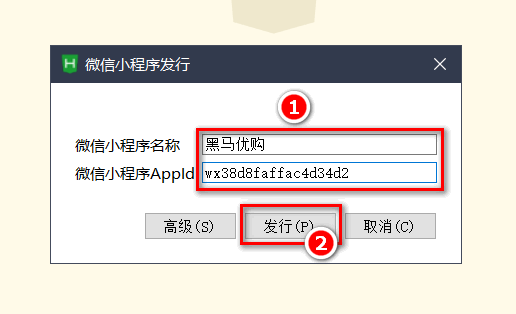


**3. 查看编译进度。** HBuilderX 控制台显示发布编译过程；确认编译成功后进入下一步。

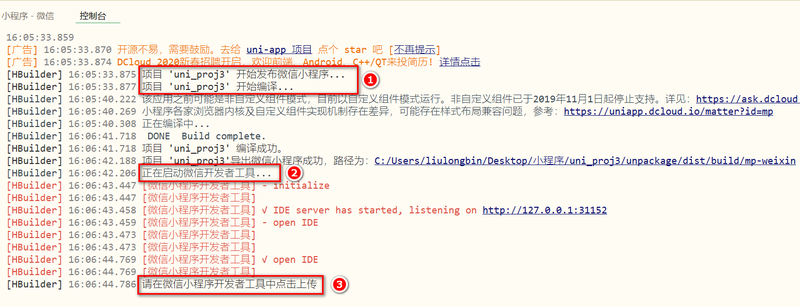


**4. 在微信开发者工具上传。** 发行编译结束后会打开新的微信开发者工具窗口，点击工具栏“上传”。

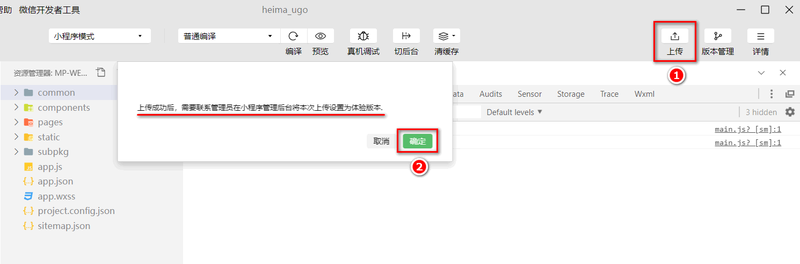


**5. 填写版本号与备注。** 输入版本号（课程示例 `1.0.0`）和本次项目备注，再点击上传。

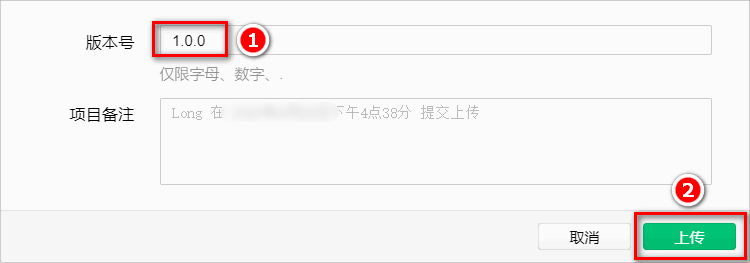


**6. 确认上传完成。** 上传结束后查看成功提示，点击确定。

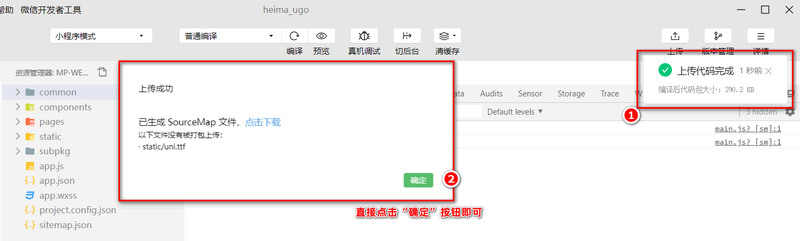


**7. 查看开发版本。** 在微信小程序后台“版本管理”中，上传的代码先出现在“开发版本”列表。上传完成还没有成为线上版本。

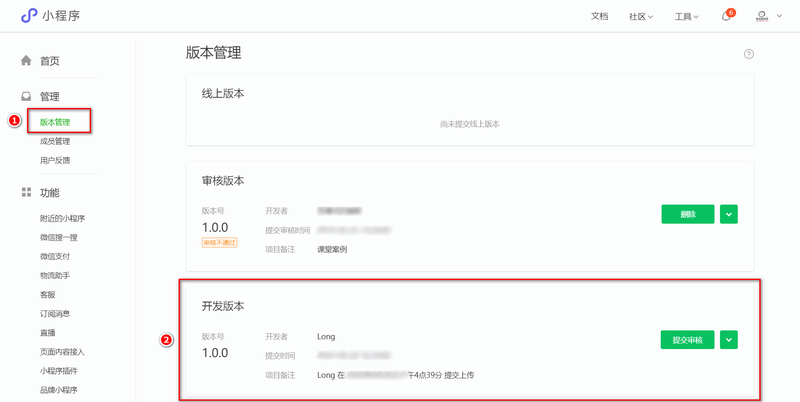


**8. 提交审核并发布。** 将开发版本提交审核，审核通过后再发布上线。

整个顺序是：发行编译 → 上传开发版本 → 提交审核 → 审核通过 → 发布线上版本。

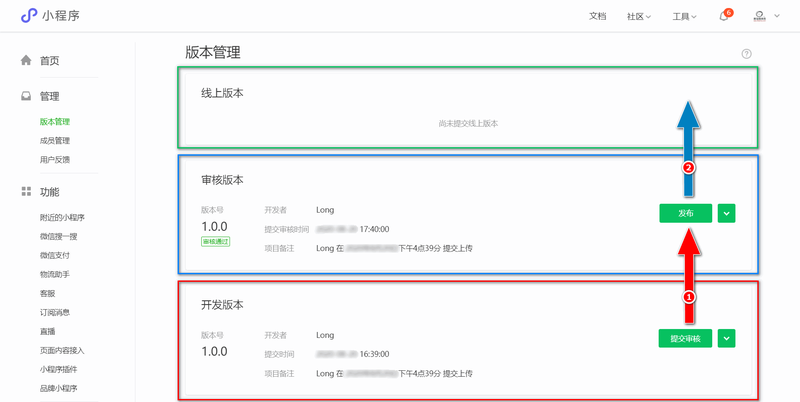


### 11.3 发布为 Android App 的流程

**1. 登录 HBuilderX。** 点击状态栏左侧“未登录”，打开账号登录对话框。

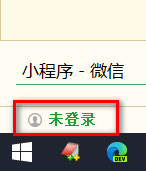


**2. 使用自己的账号登录。** 填写账号和密码，点击登录；未有账号时先注册。课程截图里的登录信息仅用于说明界面。

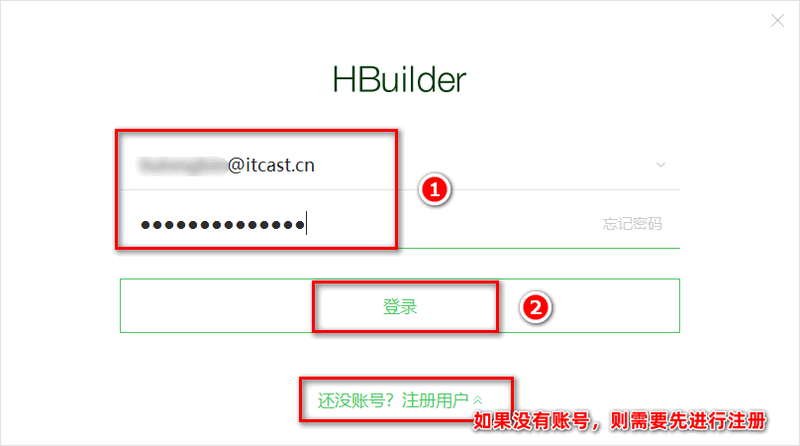


**3. 配置应用标识与名称。** 打开项目根目录的 `manifest.json`，在“基础配置”中获取 uni-app 应用标识，并填写应用名称。uni-app 应用标识与微信小程序 AppId 是不同配置项。

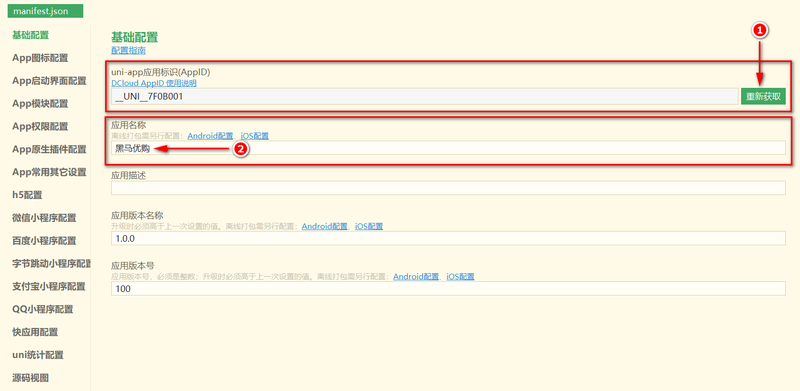


**4. 生成 App 图标。** 切换到“App 图标配置”，点击浏览选择图片，再点击“自动生成所有图标并替换”。包内资料提供 `app.png` 可供跟课选择。

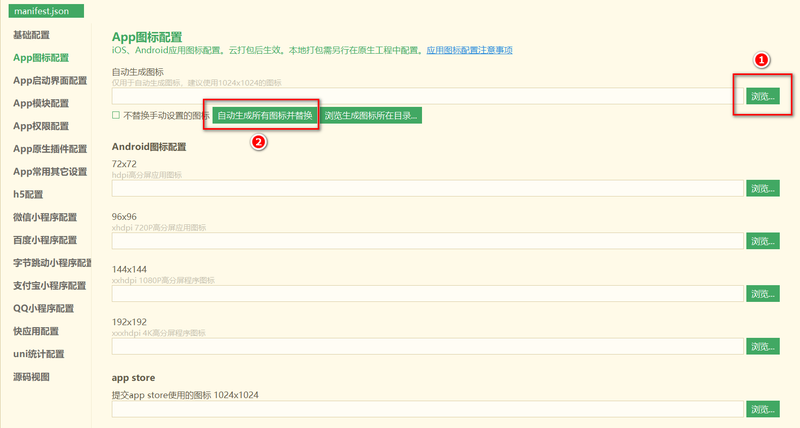


**5. 打开云打包。** 在 HBuilderX 菜单栏选择“发行 → 原生 App-云打包”。

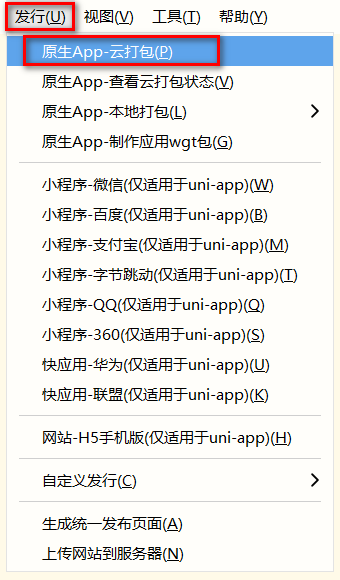


**6. 选择课程打包配置。** 勾选 Android（apk 包），确认 Android 包名，选择“使用公共测试证书”和“打正式包”，再点击“打包”。图中的公共测试证书用于本课演示，不代表完成了自己的正式签名配置。

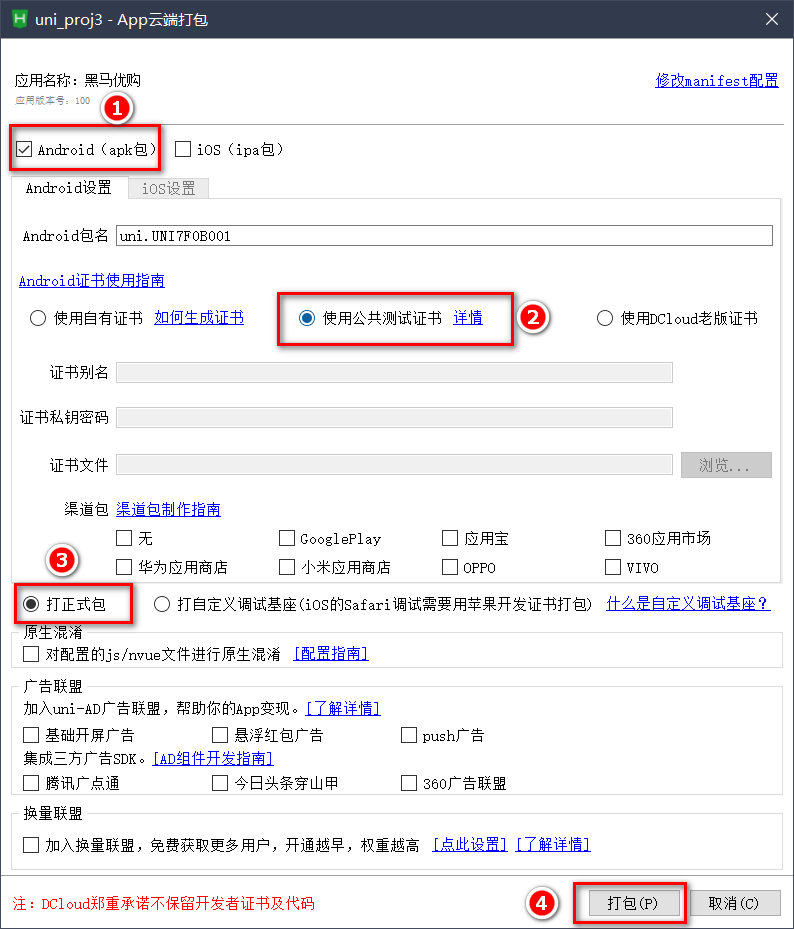


**7. 查看进度并下载 APK。** 控制台显示云打包进度，完成后点击给出的下载链接，取得 `.apk` 安装包。

**8. 在 Android 手机中安装查看。** 按课程要求检查打包后的页面效果。

> 原课没有进行多端适配，所以选择收货地址、微信登录、微信支付等功能在 App 中可能无法正常运行。打包成功只说明生成了安装包，不代表微信专用功能已适配 Android App。

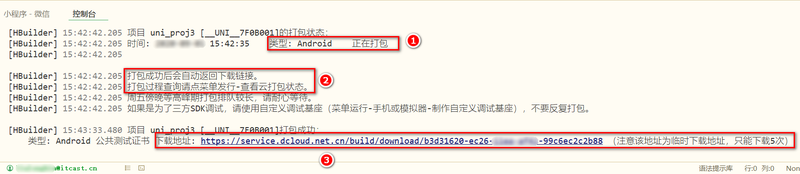


## 第 5 天完成版源码核对

### 1. 结算组件

以下是包内 `components/my-settle/my-settle.vue` 完整源码，包含全选、金额、结算前提、倒计时和支付：

```vue
<template>
  <view class="my-settle-container">
    <!-- 全选 -->
    <label class="radio" @click="changeAllState">
      <radio color="#C00000" :checked="isFullCheck" /><text>全选</text>
    </label>

    <!-- 合计 -->
    <view class="amount-box">
      合计:<text class="amount">￥{{checkedGoodsAmount}}</text>
    </view>

    <!-- 结算按钮 -->
    <view class="btn-settle" @click="settlement">结算({{checkedCount}})</view>
  </view>
</template>

<script>
  import { mapGetters, mapMutations, mapState } from 'vuex'

  export default {
    data() {
      return {
        // 倒计时的秒数
        seconds: 3,
        // 定时器的 Id
        timer: null
      };
    },
    computed: {
      ...mapGetters('m_cart', ['checkedCount', 'total', 'checkedGoodsAmount']),
      ...mapGetters('m_user', ['addstr']),
      ...mapState('m_user', ['token']),
      ...mapState('m_cart', ['cart']),
      isFullCheck() {
        return this.total === this.checkedCount
      }
    },
    methods: {
      ...mapMutations('m_cart', ['updateAllGoodsState']),
      ...mapMutations('m_user', ['updateRedirectInfo']),
      changeAllState() {
        this.updateAllGoodsState(!this.isFullCheck)
      },
      // 用户点击了结算按钮
      settlement() {
        if (!this.checkedCount) return uni.$showMsg('请选择要结算的商品！')

        if (!this.addstr) return uni.$showMsg('请选择收货地址！')

        // if (!this.token) return uni.$showMsg('请先登录！')
        if (!this.token) return this.delayNavigate()

        this.payOrder()
      },
      async payOrder() {
        // 1. 创建订单
        // 1.1 组织订单的信息对象
        const orderInfo = {
          // order_price: this.checkedGoodsAmount,
          order_price: 0.01,
          consignee_addr: this.addstr,
          goods: this.cart.filter(x => x.goods_state).map(x => ({
            goods_id: x.goods_id,
            goods_number: x.goods_count,
            goods_price: x.goods_price
          }))
        }

        // 1.2 发起请求创建订单
        const { data: res } = await uni.$http.post('/api/public/v1/my/orders/create', orderInfo)
        if (res.meta.status !== 200) return uni.$showMsg('创建订单失败！')

        // 1.3 得到服务器响应的“订单编号”
        const orderNumber = res.message.order_number

        // 2. 订单预支付
        // 2.1 发起请求获取订单的支付信息
        const { data: res2 } = await uni.$http.post('/api/public/v1/my/orders/req_unifiedorder', { order_number: orderNumber })
        // 2.2 预付订单生成失败
        if (res2.meta.status !== 200) return uni.$showMsg('预付订单生成失败！')
        // 2.3 得到订单支付相关的必要参数
        const payInfo = res2.message.pay

        // 3. 发起微信支付
        // 3.1 调用 uni.requestPayment() 发起微信支付
        const [err, succ] = await uni.requestPayment(payInfo)
        // 3.2 未完成支付
        if (err) return uni.$showMsg('订单未支付！')
        // 3.3 完成了支付，进一步查询支付的结果
        const { data: res3 } = await uni.$http.post('/api/public/v1/my/orders/chkOrder', { order_number: orderNumber })
        // 3.4 检测到订单未支付
        if (res3.meta.status !== 200) return uni.$showMsg('订单未支付！')
        // 3.5 检测到订单支付完成
        uni.showToast({
          title: '订单支付完成！',
          icon: 'success'
        })
      },
      // 延时导航到 my 页面
      delayNavigate() {
        this.seconds = 3

        this.showTips(this.seconds)

        this.timer = setInterval(() => {
          this.seconds--

          if (this.seconds <= 0) {
            clearInterval(this.timer)

            uni.switchTab({
              url: '/pages/my/my',
              success: () => {
                this.updateRedirectInfo({
                  openType: 'switchTab',
                  from: '/pages/cart/cart'
                })
              }
            })

            return
          }

          this.showTips(this.seconds)
        }, 1000)
      },
      // 展示倒计时的提示消息
      showTips(n) {
        uni.showToast({
          icon: 'none',
          title: '请登录后再结算！' + n + '秒之后自动跳转到登录页',
          mask: true,
          duration: 1500
        })
      }
    }
  }
</script>

<style lang="scss">
  .my-settle-container {
    position: fixed;
    bottom: 0;
    left: 0;
    width: 100%;
    height: 50px;
    background-color: white;
    display: flex;
    justify-content: space-between;
    align-items: center;
    font-size: 14px;
    padding-left: 5px;

    .radio {
      display: flex;
      align-items: center;
    }

    .amount-box {
      .amount {
        color: #C00000;
        font-weight: bold;
      }
    }

    .btn-settle {
      background-color: #C00000;
      height: 50px;
      color: white;
      line-height: 50px;
      padding: 0 10px;
      min-width: 100px;
      text-align: center;
    }
  }
</style>
```


### 2. 登录组件

`components/my-login/my-login.vue` 包内完成版保留授权事件的调试输出；核心顺序为保存用户信息 → 请求 Token → 保存 Token → 按重定向信息返回：

```vue
<template>
  <view class="login-container">
    <uni-icons type="contact-filled" size="100" color="#AFAFAF"></uni-icons>
    <button type="primary" class="btn-login" open-type="getUserInfo" @getuserinfo="getUserInfo">一键登录</button>
    <text class="tips-text">登录后尽享更多权益</text>
  </view>
</template>

<script>
  import { mapMutations, mapState } from 'vuex'

  export default {
    data() {
      return {

      };
    },
    computed: {
      ...mapState('m_user', ['redirectInfo'])
    },
    methods: {
      ...mapMutations('m_user', ['updateUserInfo', 'updateToken', 'updateRedirectInfo']),
      // 用户授权之后，获取用户的基本信息
      getUserInfo(e) {
        console.log(e)

        if (e.detail.errMsg === 'getUserInfo:fail auth deny') return uni.$showMsg('您取消了登录授权！')

        console.log(e.detail.userInfo)
        this.updateUserInfo(e.detail.userInfo)

        this.getToken(e.detail)
      },
      async getToken(info) {
        // 获取 code 对应的值
        const [err, res] = await uni.login().catch(err => err)

        if (err || res.errMsg !== 'login:ok') return uni.$showMsg('登录失败！')

        // 准备参数
        const query = {
          code: res.code,
          encryptedData: info.encryptedData,
          iv: info.iv,
          rawData: info.rawData,
          signature: info.signature
        }

        const { data: loginResult } = await uni.$http.post('/api/public/v1/users/wxlogin', query)
        if (loginResult.meta.status !== 200) return uni.$showMsg('登录失败！')

        // 直接把 token 保存到 vuex 中
        this.updateToken(loginResult.message.token)
        this.navigateBack()
      },
      navigateBack() {
        if (this.redirectInfo && this.redirectInfo.openType === 'switchTab') {
          uni.switchTab({
            url: this.redirectInfo.from,
            complete: () => {
              this.updateRedirectInfo(null)
            }
          })
        }
      }
    }
  }
</script>

<style lang="scss">
  .login-container {
    height: 750rpx;
    background-color: #F8F8F8;
    display: flex;
    flex-direction: column;
    justify-content: center;
    align-items: center;
    position: relative;
    overflow: hidden;

    &::after {
      content: ' ';
      display: block;
      width: 100%;
      height: 40px;
      background-color: white;
      position: absolute;
      bottom: 0;
      left: 0;
      border-radius: 100%;
      transform: translateY(50%);
    }

    .btn-login {
      width: 90%;
      border-radius: 100px;
      margin: 15px 0;
      background-color: #C00000;
    }

    .tips-text {
      font-size: 12px;
      color: gray;
    }
  }
</style>
```


### 3. 用户信息组件

`components/my-userinfo/my-userinfo.vue` 包内完成版：

```vue
<template>
  <view class="my-userinfo-container">
    <!-- 头像和昵称区域 -->
    <view class="top-box">
      <image :src="userinfo.avatarUrl" class="avatar"></image>
      <view class="nickname">{{userinfo.nickName}}</view>
    </view>

    <!-- 面板区域 -->
    <view class="panel-list">
      <!-- 第1个面板 -->
      <view class="panel">
        <view class="panel-body">
          <view class="panel-item">
            <text>8</text>
            <text>收藏的店铺</text>
          </view>
          <view class="panel-item">
            <text>14</text>
            <text>收藏的商品</text>
          </view>
          <view class="panel-item">
            <text>18</text>
            <text>关注的商品</text>
          </view>
          <view class="panel-item">
            <text>84</text>
            <text>足迹</text>
          </view>
        </view>
      </view>

      <!-- 第2个面板 -->
      <view class="panel">
        <view class="panel-title">
          我的订单
        </view>
        <view class="panel-body">
          <view class="panel-item">
            <image src="/static/my-icons/icon1.png" class="icon"></image>
            <text>待付款</text>
          </view>
          <view class="panel-item">
            <image src="/static/my-icons/icon2.png" class="icon"></image>
            <text>待收货</text>
          </view>
          <view class="panel-item">
            <image src="/static/my-icons/icon3.png" class="icon"></image>
            <text>退款/退货</text>
          </view>
          <view class="panel-item">
            <image src="/static/my-icons/icon4.png" class="icon"></image>
            <text>全部订单</text>
          </view>
        </view>
      </view>

      <!-- 第3个面板 -->
      <view class="panel">
        <view class="panel-list-item">
          <text>收货地址</text>
          <uni-icons type="arrowright" size="15"></uni-icons>
        </view>
        <view class="panel-list-item">
          <text>联系客服</text>
          <uni-icons type="arrowright" size="15"></uni-icons>
        </view>
        <view class="panel-list-item" @click="logout">
          <text>退出登录</text>
          <uni-icons type="arrowright" size="15"></uni-icons>
        </view>
      </view>
    </view>
  </view>
</template>

<script>
  import { mapState, mapMutations } from 'vuex'

  export default {
    data() {
      return {

      };
    },
    computed: {
      ...mapState('m_user', ['userinfo'])
    },
    methods: {
      ...mapMutations('m_user', ['updateAddress', 'updateUserInfo', 'updateToken']),
      async logout() {
        const [err, succ] = await uni.showModal({
          title: '提示',
          content: '确认退出登录吗？'
        }).catch(err => err)

        if (succ && succ.confirm) {
          this.updateAddress({})
          this.updateUserInfo({})
          this.updateToken('')
        }
      }
    }
  }
</script>

<style lang="scss">
  .my-userinfo-container {
    height: 100%;
    background-color: #F4F4F4;

    .top-box {
      height: 400rpx;
      background-color: #C00000;
      display: flex;
      justify-content: center;
      align-items: center;
      flex-direction: column;

      .avatar {
        width: 90px;
        height: 90px;
        border-radius: 45px;
        border: 2px solid #FFF;
        box-shadow: 0 1px 5px black;
      }

      .nickname {
        font-size: 16px;
        color: #FFF;
        font-weight: bold;
        margin-top: 10px;
      }
    }
  }

  .panel-list {
    padding: 0 10px;
    position: relative;
    top: -10px;

    .panel {
      background-color: white;
      border-radius: 3px;
      margin-bottom: 8px;

      .panel-title {
        line-height: 45px;
        padding-left: 10px;
        font-size: 15px;
        border-bottom: 1px solid #F4F4F4;
      }

      .panel-body {
        display: flex;
        justify-content: space-around;

        .panel-item {
          display: flex;
          flex-direction: column;
          align-items: center;
          justify-content: space-around;
          padding: 10px 0;
          font-size: 13px;

          .icon {
            width: 35px;
            height: 35px;
          }
        }
      }
    }
  }

  .panel-list-item {
    display: flex;
    justify-content: space-between;
    align-items: center;
    font-size: 15px;
    padding: 0 10px;
    line-height: 45px;
  }
</style>
```


### 4. 购物车 Store

`store/cart.js` 包内完成版。原有 `total` 在这里也改写为 `reduce`，仍然统计所有商品的总件数：

```javascript
export default {
  namespaced: true,

  state: () => ({
    // 购物车的数组，用来存储购物车中每个商品的信息对象
    // 每个商品的信息对象，都包含如下 6 个属性：
    // { goods_id, goods_name, goods_price, goods_count, goods_small_logo, goods_state }
    cart: JSON.parse(uni.getStorageSync('cart') || '[]')
  }),

  mutations: {
    addToCart(state, goods) {
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if (!findResult) {
        state.cart.push(goods)
      } else {
        findResult.goods_count++
      }

      this.commit('m_cart/saveToStorage')
    },
    saveToStorage(state) {
      uni.setStorageSync('cart', JSON.stringify(state.cart))
    },
    // 更新购物车中商品的勾选状态
    updateGoodsState(state, goods) {
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if (findResult) {
        findResult.goods_state = goods.goods_state

        this.commit('m_cart/saveToStorage')
      }
    },
    // 更新商品的数量
    updateGoodsCount(state, goods) {
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if (findResult) {
        findResult.goods_count = goods.goods_count

        this.commit('m_cart/saveToStorage')
      }
    },
    // 根据 Id 删除对应的商品
    removeGoodsById(state, goods_id) {
      state.cart = state.cart.filter(x => x.goods_id !== goods_id)

      this.commit('m_cart/saveToStorage')
    },
    // 更新购物车中所有商品的勾选状态
    updateAllGoodsState(state, newState) {
      state.cart.forEach(x => x.goods_state = newState)

      this.commit('m_cart/saveToStorage')
    }
  },

  getters: {
    // 购物车中所有商品的总数量
    total(state) {
      // let c = 0
      // state.cart.forEach(x => c += x.goods_count)
      // return c

      return state.cart.reduce((total, item) => total += item.goods_count, 0)
    },
    // 购物车中已勾选商品的总数量
    checkedCount(state) {
      return state.cart.filter(x => x.goods_state).reduce((total, item) => total += item.goods_count, 0)
    },
    // 已勾选商品的总价格
    checkedGoodsAmount(state) {
      return state.cart.filter(x => x.goods_state).reduce((total, item) => total += item.goods_count * item.goods_price, 0).toFixed(2)
    }
  }
}
```


### 5. 用户 Store

`store/user.js` 包内完成版。地址、用户信息和 Token 持久化，`redirectInfo` 只存于当前 Store；包内还保留了更新重定向信息时的打印：

```javascript
export default {
  // 开启命名空间
  namespaced: true,

  // 数据
  state: () => ({
    address: JSON.parse(uni.getStorageSync('address') || '{}'),
    token: uni.getStorageSync('token') || '',
    // 用户的信息对象
    userinfo: JSON.parse(uni.getStorageSync('userinfo') || '{}'),
    // 重定向的 Object 对象
    redirectInfo: null
  }),

  // 方法
  mutations: {
    // 更新收货地址
    updateAddress(state, address) {
      state.address = address

      this.commit('m_user/saveAddressToStorage')
    },
    // 持久化存储 address
    saveAddressToStorage(state) {
      uni.setStorageSync('address', JSON.stringify(state.address))
    },
    updateUserInfo(state, userinfo) {
      state.userinfo = userinfo

      this.commit('m_user/saveUserInfoToStorage')
    },
    saveUserInfoToStorage(state) {
      uni.setStorageSync('userinfo', JSON.stringify(state.userinfo))
    },
    updateToken(state, token) {
      state.token = token
      this.commit('m_user/saveTokenToStorage')
    },
    saveTokenToStorage(state) {
      uni.setStorageSync('token', state.token)
    },
    updateRedirectInfo(state, info) {
      state.redirectInfo = info
      console.log(state.redirectInfo)
    }
  },

  getters: {
    // 收货地址
    addstr(state) {
      if (!state.address.provinceName) return ''

      return state.address.provinceName + state.address.cityName + state.address.countyName + state.address.detailInfo
    }
  }
}
```


### 6. 请求与徽标

`main.js` 保留原请求根路径、loading 和消息提示封装，增加受限接口的 Token 请求头：

```javascript
import Vue from 'vue'
import App from './App'
import store from '@/store/store.js'

// 导入网络请求的包
import { $http } from '@escook/request-miniprogram'

uni.$http = $http

// 请求的根路径
$http.baseUrl = 'https://www.uinav.com'

// 请求拦截器
$http.beforeRequest = function(options) {
  uni.showLoading({
    title: '数据加载中...'
  })

  // console.log(store)

  // 判断当前请求的是否为有权限的接口
  if (options.url.indexOf('/my/') !== -1) {
    options.header = {
      Authorization: store.state.m_user.token
    }
  }
}

// 响应拦截器
$http.afterRequest = function() {
  uni.hideLoading()
}

// 封装弹框的方法
uni.$showMsg = function(title = '数据请求失败！', duration = 1500) {
  uni.showToast({
    title,
    duration,
    icon: 'none'
  })
}

Vue.config.productionTip = false

App.mpType = 'app'

const app = new Vue({
  ...App,
  store
})
app.$mount()
```

`mixins/tabbar-badge.js` 完成版：

```javascript
import { mapGetters } from 'vuex'

export default {
  computed: {
    ...mapGetters('m_cart', ['total'])
  },
  watch: {
    total() {
      this.setBadge()
    }
  },
  onShow() {
    this.setBadge()
  },
  methods: {
    setBadge() {
      uni.setTabBarBadge({
        index: 2,
        text: this.total + ''
      })
    }
  }
}
```


### 7. 购物车与我的页面

`pages/cart/cart.vue` 完成版保留 09 的地址和商品操作，新增结算组件及空状态：

```vue
<template>
  <view class="cart-container" v-if="cart.length !== 0">
    <!-- 收货地址组件 -->
    <my-address></my-address>

    <!-- 商品列表的标题区域 -->
    <view class="cart-title">
      <!-- 左侧的图标 -->
      <uni-icons type="shop" size="18"></uni-icons>
      <!-- 右侧的文本 -->
      <text class="cart-title-text">购物车</text>
    </view>

    <!-- 循环渲染购物车中的商品信息 -->
    <uni-swipe-action>
      <block v-for="(goods, i) in cart" :key="i">
        <uni-swipe-action-item :options="options" @click="swipeItemClickHandler(goods)">
          <my-goods :goods="goods" :show-radio="true" :show-num="true" @radio-change="radioChangeHandler" @num-change="numberChangeHandler"></my-goods>
        </uni-swipe-action-item>
      </block>
    </uni-swipe-action>

    <!-- 使用自定义的结算组件 -->
    <my-settle></my-settle>
  </view>

  <!-- 空白购物车的区域 -->
  <view class="empty-cart" v-else>
    <image src="/static/cart_empty@2x.png" class="empty-img"></image>
    <text class="tip-text">空空如也~</text>
  </view>
</template>

<script>
  import badgeMix from '@/mixins/tabbar-badge.js'
  import { mapState, mapMutations } from 'vuex'

  export default {
    mixins: [badgeMix],
    computed: {
      ...mapState('m_cart', ['cart'])
    },
    data() {
      return {
        options: [{
          text: '删除',
          style: {
            backgroundColor: '#C00000'
          }
        }]
      };
    },
    methods: {
      ...mapMutations('m_cart', ['updateGoodsState', 'updateGoodsCount', 'removeGoodsById']),
      radioChangeHandler(e) {
        this.updateGoodsState(e)
      },
      numberChangeHandler(e) {
        this.updateGoodsCount(e)
      },
      swipeItemClickHandler(goods) {
        this.removeGoodsById(goods.goods_id)
      }
    }
  }
</script>

<style lang="scss">
  .cart-container {
    padding-bottom: 50px;
  }

  .cart-title {
    height: 40px;
    display: flex;
    align-items: center;
    padding-left: 5px;
    border-bottom: 1px solid #EFEFEF;

    .cart-title-text {
      font-size: 14px;
      margin-left: 10px;
    }
  }

  .empty-cart {
    display: flex;
    flex-direction: column;
    align-items: center;
    padding-top: 150px;

    .empty-img {
      width: 90px;
      height: 90px;
    }

    .tip-text {
      font-size: 12px;
      color: gray;
      margin-top: 15px;
    }
  }
</style>
```


`pages/my/my.vue` 完成版：

```vue
<template>
  <view class="my-container">
    <my-login v-if="!token"></my-login>

    <my-userinfo v-else></my-userinfo>
  </view>
</template>

<script>
  import badgeMix from '@/mixins/tabbar-badge.js'
  import { mapState } from 'vuex'

  export default {
    mixins: [badgeMix],
    data() {
      return {

      };
    },
    computed: {
      ...mapState('m_user', ['token'])
    }
  }
</script>

<style lang="scss">
  page,
  .my-container {
    height: 100%;
  }
</style>
```


## 跟课验证

| 操作 | 应检查的效果 |
| --- | --- |
| 进入有商品的购物车 | 底部结算栏固定，最后一行商品未被遮住 |
| 修改单个商品的勾选和数量 | 结算件数、金额随之更新 |
| 点击全选与反选 | 各行勾选状态一致改变，并保存在缓存 |
| 修改购物车数量 | tabBar 徽标随 `total` 变化刷新 |
| 删除最后一个商品 | 显示“空空如也~”，结算栏隐藏 |
| 未勾选商品点击结算 | 先提示选择商品 |
| 有选中商品但无地址 | 提示选择地址 |
| 有商品和地址但未登录 | 提示 3、2、1 秒，随后切换到“我的”页 |
| 拒绝用户信息授权 | 提示取消登录授权 |
| 登录接口成功并保存 Token | 显示头像昵称和用户面板，重启后读取缓存 |
| 由结算倒计时进入后登录成功 | 返回购物车，清空重定向信息 |
| 直接进入“我的”页登录 | 没有返回信息时，留在当前页 |
| 取消退出确认 | 保留原用户数据 |
| 确认退出登录 | 清空用户信息、Token、地址，显示登录界面 |
| 查看订单相关请求 | `/my/` 接口带 `Authorization`；仅提交勾选商品 |
| 核对演示订单 | 测试金额为 0.01 元，数量字段用 `goods_number` |
| 创建订单或预支付失败 | 提示并停止后续步骤 |
| 支付取消或服务端确认失败 | 提示订单未支付 |
| 服务端支付状态为 200 | 显示成功提示 |
| 跟课发行小程序 | 编译成功，上传后先成为开发版本 |
| 提交审核并发布 | 审核通过后才成为线上版本 |
| 跟课 Android 云打包 | 获得 APK，并检查未适配的平台功能边界 |

本笔记已核对包内讲义、API 字段和完成版源码，校验 JSON、Notebook 格式、代码围栏、静态 JavaScript 语法与内嵌图片。未在微信开发者工具中运行，没有验证真实登录、付款、上传或发布；上表是跟课时应检查的结果。

至此，基础 5 天对应 01–05，项目 5 天对应 06–10。
